# Hierarchical Risk Parity (Dendrogram + Weights)

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Shows how hierarchical risk parity (López de Prado, 2016) builds a portfolio. A dendrogram clusters assets by correlation, the reordered correlation matrix shows the clusters as blocks, and the weights panel shows how risk is split across clusters, then within them. The method needs no inversion of the covariance matrix, so it avoids the unstable, concentrated weights of classic mean-variance optimisation.

## When to use

- Explain or audit an HRP (or other cluster-based) allocation
- Show the correlation structure of a multi-asset universe
- Compare risk-based weighting schemes side by side

## Avoid when

- The audience only needs the final weights (a simple bar chart)
- There are fewer than ~6 assets (the hierarchy is trivial)

## Alternatives

- Correlation network (minimum spanning tree)
- Risk contribution chart
- Clustered heatmap (seaborn clustermap)

## Design tips

- Use the same asset order in the heatmap and the weights panel
- Diverging colors centred on zero correlation, one hue for each sign
- Compare HRP with simple baselines (equal weight, inverse volatility)

## Example

Simulated daily returns for 12 assets in three groups (equities, bonds, commodities) over three years. HRP is implemented from scratch with numpy/scipy (single linkage, quasi-diagonalisation, recursive bisection). Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy.cluster.hierarchy import dendrogram, leaves_list, linkage
from scipy.spatial.distance import squareform

### Data

In [2]:
rng = np.random.default_rng(8)
groups = {"US eq.": 0.011, "EU eq.": 0.012, "JP eq.": 0.012, "EM eq.": 0.015,
          "Treasury": 0.004, "Bund": 0.0035, "IG credit": 0.005, "TIPS": 0.0045,
          "Oil": 0.022, "Gold": 0.010, "Copper": 0.016, "Agri": 0.013}
cluster = ["eq"] * 4 + ["bond"] * 4 + ["cmd"] * 4
n = 756
factors = {k: rng.standard_normal(n) for k in ("eq", "bond", "cmd")}
loading = {"eq": 0.85, "bond": 0.75, "cmd": 0.55}
rets = pd.DataFrame({
    name: vol * (loading[c] * factors[c] + np.sqrt(1 - loading[c] ** 2) * rng.standard_normal(n))
    for (name, vol), c in zip(groups.items(), cluster)})
rets.std().mul(np.sqrt(252)).round(3).rename("annual vol")

US eq.       0.179
EU eq.       0.188
JP eq.       0.189
EM eq.       0.241
Treasury     0.064
Bund         0.057
IG credit    0.079
TIPS         0.069
Oil          0.349
Gold         0.150
Copper       0.259
Agri         0.209
Name: annual vol, dtype: float64

### Plot

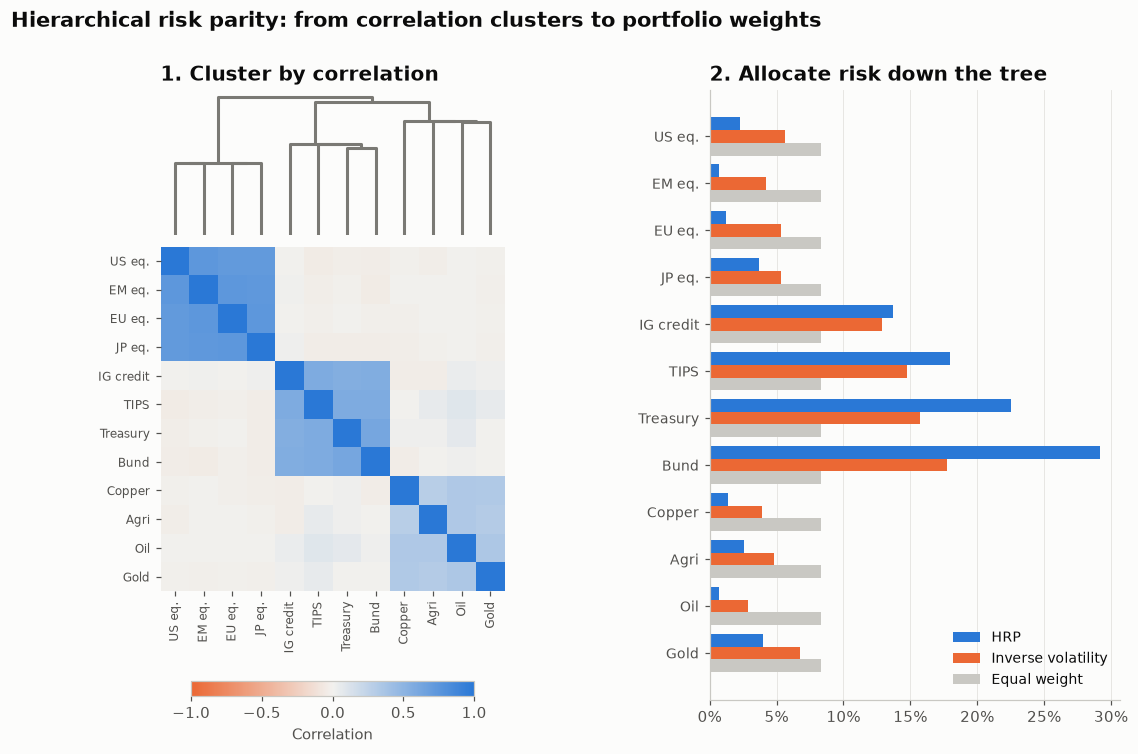

In [3]:
cov, corr = rets.cov(), rets.corr()
dist = np.sqrt(0.5 * (1 - corr.clip(-1, 1)))
link = linkage(squareform(dist.values, checks=False), method="single")
order = list(corr.index[leaves_list(link)])


def cluster_var(cols):
    c = cov.loc[cols, cols].values
    w = 1 / np.diag(c)
    w /= w.sum()
    return w @ c @ w


def hrp_weights(order):
    w = pd.Series(1.0, index=order)
    stack = [order]
    while stack:
        items = stack.pop()
        if len(items) < 2:
            continue
        left, right = items[: len(items) // 2], items[len(items) // 2:]
        vl, vr = cluster_var(left), cluster_var(right)
        alpha = 1 - vl / (vl + vr)
        w[left] *= alpha
        w[right] *= 1 - alpha
        stack += [left, right]
    return w


weights = pd.DataFrame({
    "HRP": hrp_weights(order),
    "Inverse volatility": (1 / rets.std()) / (1 / rets.std()).sum(),
    "Equal weight": 1 / len(order)}).loc[order]

fig = plt.figure(figsize=(12, 7.2))
gs = fig.add_gridspec(2, 2, width_ratios=[1.15, 1], height_ratios=[0.32, 1], wspace=0.32, hspace=0.04)
ax_d = fig.add_subplot(gs[0, 0])
dendrogram(link, ax=ax_d, color_threshold=0, above_threshold_color="#7a7974", no_labels=True)
ax_d.set_axis_off()
ax_d.set_title("1. Cluster by correlation", loc="left")

ax_h = fig.add_subplot(gs[1, 0])
cmap = LinearSegmentedColormap.from_list("div", [PALETTE[1], "#f2f1ee", PALETTE[0]])
im = ax_h.imshow(corr.loc[order, order], cmap=cmap, norm=TwoSlopeNorm(0, -1, 1))
ax_h.set_xticks(range(len(order)), order, rotation=90, fontsize=8)
ax_h.set_yticks(range(len(order)), order, fontsize=8)
ax_h.grid(False)
for sp in ax_h.spines.values():
    sp.set_visible(False)
fig.colorbar(im, ax=ax_h, orientation="horizontal", fraction=0.04, pad=0.2, shrink=0.6, label="Correlation")

ax_w = fig.add_subplot(gs[:, 1])
y = np.arange(len(order))
h = 0.27
for k, (col, color) in enumerate(zip(weights.columns, [PALETTE[0], PALETTE[1], "#c9c8c3"])):
    ax_w.barh(y + (k - 1) * h, weights[col], height=h, color=color, label=col)
ax_w.set_yticks(y, order, fontsize=9)
ax_w.invert_yaxis()
ax_w.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax_w.grid(axis="y", visible=False)
ax_w.set_title("2. Allocate risk down the tree", loc="left")
ax_w.legend(loc="lower right", fontsize=9)
fig.suptitle("Hierarchical risk parity: from correlation clusters to portfolio weights",
             x=0.06, ha="left", fontsize=14, fontweight="bold")
fig.canvas.draw()                                 # align dendrogram leaves with heatmap columns
ph, pdg = ax_h.get_position(), ax_d.get_position()
ax_d.set_position([ph.x0, pdg.y0, ph.width, pdg.height])
plt.show()

## How to read it

The dendrogram joins the most correlated assets first; the three big branches are equities, bonds and commodities, which appear as bright blocks on the diagonal of the heatmap. In the weights panel, HRP puts about 83% in the low-volatility bonds, against 61% for inverse-volatility and 33% for equal weighting, because every split divides capital by inverse variance. Within each cluster the calmest asset (Bund, Gold, JP eq.) gets the largest HRP weight.

## Reference

This method comes from the research literature:

- López de Prado, M. (2016). Building diversified portfolios that outperform out of sample. The Journal of Portfolio Management 42(4), 59–69. <https://doi.org/10.3905/jpm.2016.42.4.059>

---
Standalone script: [`hrp_dendrogram.py`](hrp_dendrogram.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)